# 02 · Exploratory Data Analysis (EDA)
**Climate Trend Analyzer** — step 2 of 5

### What is EDA for?
EDA is *reconnaissance*: before we model anything we need to know what the
data looks like, what varies, what repeats, and what is unusual. Four
questions to answer:

1. What is the shape and spread of each variable?
2. Which variables move together (correlation)?
3. How does the data behave across the calendar (seasonality)?
4. Which years stand out?

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists():          # allow running from anywhere
    PROJECT_ROOT = Path(r"/home/user/Climate-Trend-Analyzer")
    sys.path.insert(0, str(PROJECT_ROOT))
else:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.1)

from src import config as cfg
from src import data_loader, preprocessing, features, eda, trend_analysis
from src import anomaly_detection, forecasting, insights, visualizations as viz

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
print("Project root:", PROJECT_ROOT)

Project root: /home/user/Climate-Trend-Analyzer


In [2]:
clean = data_loader.load_clean(cfg.CLEAN_CSV)
feat  = features.build_features(clean)
feat  = features.add_cyclical_month(feat)
feat.head()

[data_loader] Loaded clean dataset: /home/user/Climate-Trend-Analyzer/data/processed/climate_clean.csv -> shape (2700, 17)


,date,region,country,latitude,longitude,temp_mean_c,temp_min_c,temp_max_c,rainfall_mm,humidity_pct,co2_ppm,sea_level_mm,sim_heatwave,sim_drought,year,month,data_quality_flag,quarter,season,decade,...,rain_pct_of_normal,rain_anomaly_z,temp_mean_c_lag1,temp_mean_c_lag2,temp_mean_c_lag3,temp_mean_c_lag12,rainfall_mm_lag1,rainfall_mm_lag2,rainfall_mm_lag3,rainfall_mm_lag12,heatwave_month,drought_month,heatwave_event,drought_event,extreme_event,enso_proxy,co2_change_rate,sea_level_change_rate,month_sin,month_cos
0,1980-01-01,Hyderabad,India,17.4,78.5,26.94,21.41,32.27,131.1,61.5,338.58,-1.8,0,0,1980,1,original,1,Winter,1980,...,183.550605,0.914497,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0,0,0,NaN,NaN,NaN,0.500000,8.660254e-01
1,1980-02-01,Hyderabad,India,17.4,78.5,24.72,20.19,28.58,97.5,59.4,339.69,-1.2,0,0,1980,2,original,1,Winter,1980,...,107.315820,0.096756,26.94,NaN,NaN,NaN,131.1,NaN,NaN,NaN,0,0,0,0,0,-0.285659,NaN,NaN,0.866025,5.000000e-01
2,1980-03-01,Hyderabad,India,17.4,78.5,20.22,16.90,23.48,28.7,67.0,338.19,-0.9,0,0,1980,3,original,1,Spring,1980,...,26.883287,-0.924654,24.72,26.94,NaN,NaN,97.5,131.1,NaN,NaN,0,1,0,0,0,-0.321096,NaN,NaN,1.000000,6.123234e-17
3,1980-04-01,Hyderabad,India,17.4,78.5,19.48,14.98,23.06,25.6,74.1,338.72,1.0,0,0,1980,4,original,2,Spring,1980,...,20.098398,-1.048162,20.22,24.72,26.94,NaN,28.7,97.5,131.1,NaN,0,1,0,0,0,-0.612133,NaN,NaN,0.866025,-5.000000e-01
4,1980-05-01,Hyderabad,India,17.4,78.5,21.70,18.03,25.94,49.7,62.3,338.92,-0.4,0,0,1980,5,original,2,Spring,1980,...,36.510709,-0.814649,19.48,20.22,24.72,NaN,25.6,28.7,97.5,NaN,0,1,0,1,1,-0.857037,NaN,NaN,0.500000,-8.660254e-01


## 2.1 Descriptive statistics

In [3]:
bundle = eda.run_eda(feat)
bundle["summary"]

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis,missing,unit
temp_mean_c,2700.0,20.075,8.812,-0.50,13.812,22.000,27.282,36.87,-0.479,-0.805,0,degC
temp_min_c,2700.0,15.633,8.898,-6.27,9.500,17.505,22.572,33.07,-0.491,-0.675,0,degC
temp_max_c,2700.0,24.517,8.875,2.90,17.920,26.100,32.082,41.36,-0.444,-0.884,0,degC
rainfall_mm,2700.0,109.655,130.595,0.20,30.975,67.650,138.350,1925.30,3.512,23.366,0,mm
humidity_pct,2700.0,69.027,10.069,43.10,61.300,68.400,77.800,90.40,-0.076,-0.923,0,%
co2_ppm,2700.0,395.676,36.834,334.92,363.288,392.905,426.912,466.21,0.178,-1.172,0,ppm
sea_level_mm,2700.0,58.033,41.182,-2.60,21.175,52.150,91.600,140.60,0.337,-1.110,0,mm


Text(0, 0.5, 'density')

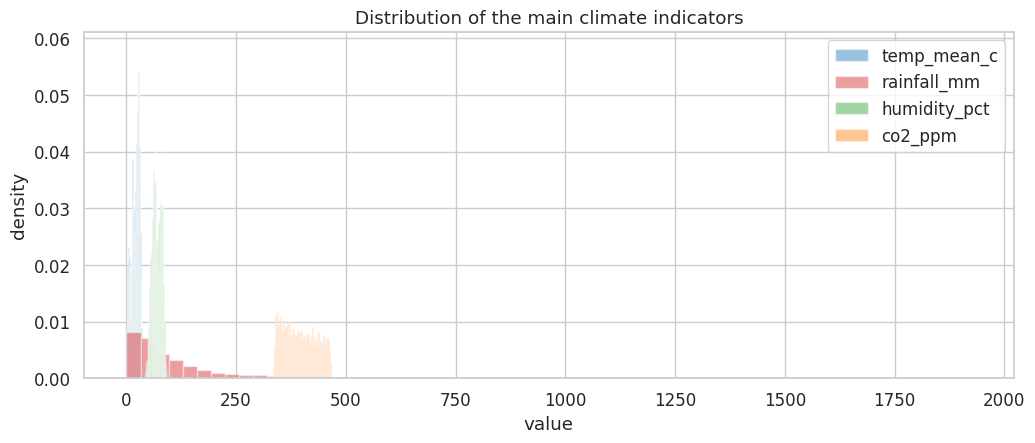

In [4]:
fig, ax = plt.subplots(figsize=(12, 4.5))
for c in ["temp_mean_c", "rainfall_mm", "humidity_pct", "co2_ppm"]:
    ax.hist(feat[c].dropna(), bins=60, alpha=0.45, label=c, density=True)
ax.legend(); ax.set_title("Distribution of the main climate indicators")
ax.set_xlabel("value"); ax.set_ylabel("density")

## 2.2 Correlations - the driver question

In [5]:
bundle["correlations"]

,temp_mean_c,temp_min_c,temp_max_c,rainfall_mm,humidity_pct,co2_ppm,sea_level_mm
temp_mean_c,1.000,0.993,0.992,0.035,-0.262,0.028,0.041
temp_min_c,0.993,1.000,0.976,0.035,-0.263,0.026,0.039
temp_max_c,0.992,0.976,1.000,0.036,-0.261,0.027,0.040
rainfall_mm,0.035,0.035,0.036,1.000,0.316,-0.027,-0.023
humidity_pct,-0.262,-0.263,-0.261,0.316,1.000,-0.045,-0.044
co2_ppm,0.028,0.026,0.027,-0.027,-0.045,1.000,0.997
sea_level_mm,0.041,0.039,0.040,-0.023,-0.044,0.997,1.000


Text(0.5, 1.0, 'Which climate variables move together?')

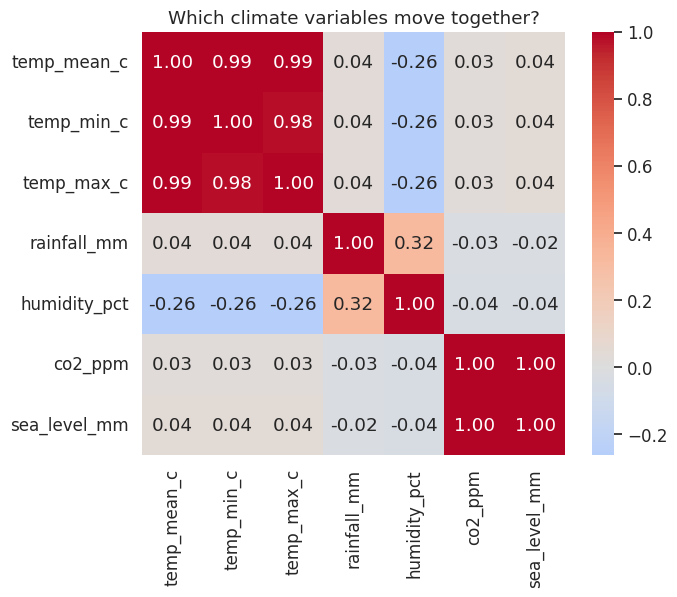

In [6]:
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(bundle["correlations"], annot=True, fmt=".2f", cmap="coolwarm",
            center=0, square=True, ax=ax)
ax.set_title("Which climate variables move together?")

> **CO₂ vs temperature is the classic relationship.** Remember the caveat:
> correlation is not causation - both are driven by the same underlying
> energy balance, and the CO₂ series is a *global driver* while temperature
> is also shaped by local circulation.

## 2.3 Seasonality

In [7]:
bundle["seasonal"]

,month,temp_mean_c,rainfall_mm,humidity_pct,month_name
0,1,22.603,111.807,66.120,Jan
1,2,21.569,125.660,67.208,Feb
2,3,20.101,138.598,68.955,Mar
3,4,18.707,129.367,70.638,Apr
4,5,17.616,127.951,71.788,May
5,6,17.204,135.372,72.382,Jun
6,7,17.586,105.094,71.721,Jul
7,8,18.524,91.072,71.001,Aug
8,9,19.924,85.081,69.543,Sep
9,10,21.487,84.818,67.548,Oct


In [8]:
viz.plot_seasonal_profile(feat)

[viz] saved 05_seasonal_profile.png


PosixPath('/home/user/Climate-Trend-Analyzer/outputs/figures/05_seasonal_profile.png')

## 2.4 Yearly aggregates

In [9]:
bundle["global_yearly"].tail(15)

,year,temp_mean,rainfall_total,humidity_mean,co2_mean,sea_level_mean,temp_anomaly,extreme_events
30,2010,20.665,1870.84,67.782,416.613,79.748,0.590,2
31,2011,20.724,1589.18,68.351,419.676,83.454,0.649,2
32,2012,19.930,1350.86,69.325,422.815,87.120,-0.146,0
33,2013,20.113,1206.26,68.715,426.045,90.807,0.038,1
34,2014,20.593,1194.32,68.870,429.177,95.348,0.518,1
35,2015,20.824,1326.18,67.570,432.438,99.058,0.749,1
36,2016,20.298,1218.62,68.795,435.772,103.033,0.223,4
37,2017,20.535,990.30,68.745,439.111,107.145,0.460,3
38,2018,20.255,1310.42,68.635,442.317,111.418,0.180,1
39,2019,21.311,1602.82,67.935,445.573,115.532,1.235,6


In [10]:
viz.plot_yearly_comparison(feat)

[viz] saved 06_yearly_comparison.png


PosixPath('/home/user/Climate-Trend-Analyzer/outputs/figures/06_yearly_comparison.png')

### ✅ Checkpoint
* Clear seasonal cycle in temperature and rainfall
* CO₂ and temperature correlate strongly
* Yearly aggregates show a visible warming pattern